# 1. Importuri


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, classification_report
import tensorflow as tf
from tensorflow import keras
from keras import layers



# 2. Incarcarea Datelor

In [ ]:
df = pd.read_csv('dataset_final.csv')
print(df.shape)
print(df.head())
print(df.label.value_counts())

(538327, 9)
     ax    ay     az    gx    gy    gz   temp  label  pwm_speed
0  0.08  1.12 -10.57 -0.08 -0.02 -0.02  24.09      2        160
1  0.11  1.30 -10.88 -0.10  0.05 -0.01  24.10      2        160
2  0.42  1.14 -10.63 -0.05  0.02 -0.01  24.09      2        160
3  0.23  0.94 -10.50 -0.10  0.05 -0.01  24.09      2        160
4  0.12  1.15 -10.74 -0.09  0.00 -0.02  24.10      2        160
label
2    129216
1    129216
3    129215
4    129144
0     21536
Name: count, dtype: int64


# 3. Pregatirea Datelor

In [ ]:
feature_columns = [col for col in df.columns if col not in ['label']]
label_column = 'label'
X = df[feature_columns].values
y = df[label_column].values
print(X.shape, y.shape)
window_size = 128
step_size = 64
print(feature_columns)

(538327, 8) (538327,)
['ax', 'ay', 'az', 'gx', 'gy', 'gz', 'temp', 'pwm_speed']


# 4. Normalizarea Datelor

In [ ]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X).astype(np.float32)
X = X_scaled
print(scaler.mean_, scaler.scale_)

[ 1.60726547e-01  1.25892021e+00 -1.06241571e+01 -8.21001362e-02
  2.17937053e-02 -1.04359061e-02  2.41777059e+01  2.00802681e+02] [3.18629161e-01 3.98620188e-01 2.59766639e-01 2.31416340e-02
 2.99047361e-02 5.70753398e-03 6.43858877e-01 5.21887533e+01]


# 5. Window Slicing

In [ ]:
def window_slicing(X, y, window_size, step_size):
    X_windows = []
    y_windows = []
    for start in range(0, X.shape[0] - window_size + 1, step_size):
        end = start + window_size
        X_windows.append(X[start:end])
        window_labels = y[start:end].astype(int)
        majority_label = np.bincount(window_labels).argmax() 
        y_windows.append(majority_label)
    return np.array(X_windows), np.array(y_windows)

X_windows, y_windows = window_slicing(X, y, window_size, step_size)
print(X_windows.shape, y_windows.shape)

(8410, 128, 8) (8410,)


# 6. Split + Shuffle

In [ ]:
X_train, X_val, y_train, y_val = train_test_split(
    X_windows, y_windows, test_size=0.2, random_state=42, stratify=y_windows
)

# 7. CNN 1D

In [ ]:
model = keras.Sequential([
    layers.Input(shape=(window_size, X.shape[1])),
    layers.Conv1D(64, kernel_size=3, activation='relu'),
    layers.MaxPooling1D(pool_size=2),
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dense(len(np.unique(y)), activation='softmax')

])
model.compile(
    loss='sparse_categorical_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=20,
    batch_size=32
)
val_loss, val_accuracy = model.evaluate(X_val, y_val)
print(f'Validation Loss: {val_loss}, Validation Accuracy: {val_accuracy}')

Epoch 1/20
211/211 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9804 - loss: 0.0633 - val_accuracy: 0.9982 - val_loss: 0.0074
Epoch 2/20
211/211 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9804 - loss: 0.0633 - val_accuracy: 0.9982 - val_loss: 0.0074
Epoch 2/20
211/211 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9999 - loss: 0.0015 - val_accuracy: 1.0000 - val_loss: 6.7582e-04
Epoch 3/20
211/211 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9999 - loss: 0.0015 - val_accuracy: 1.0000 - val_loss: 6.7582e-04
Epoch 3/20
211/211 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 1.0000 - loss: 2.9650e-04 - val_accuracy: 1.0000 - val_loss: 4.1468e-04
Epoch 4/20
211/211 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 1.0000 - loss: 2.9650e-04 - val_accuracy: 1.0000 - val_loss: 4.1468e-04
Epoch 4/20
211/211 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 1.0000 - loss: 1.6881e-04 - val_accuracy: 1.0000 - val_loss: 3.2274e-04
Epoch 5/20
211/211 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 1.0000 -

# 8. Evaluare detaliata

53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        67
           1       1.00      1.00      1.00       404
           2       1.00      1.00      1.00       404
           3       1.00      1.00      1.00       404
           4       1.00      1.00      1.00       403

    accuracy                           1.00      1682
   macro avg       1.00      1.00      1.00      1682
weighted avg       1.00      1.00      1.00      1682

Confusion matrix:
 [[ 67   0   0   0   0]
 [  0 404   0   0   0]
 [  0   0 404   0   0]
 [  0   0   0 404   0]
 [  0   0   0   0 403]]
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        67
           1       1.00      1.00      1.00       404
           2       1.00      1.00      1.00       404
           3       1.00      1.00      1.00       404
           4       1.00    

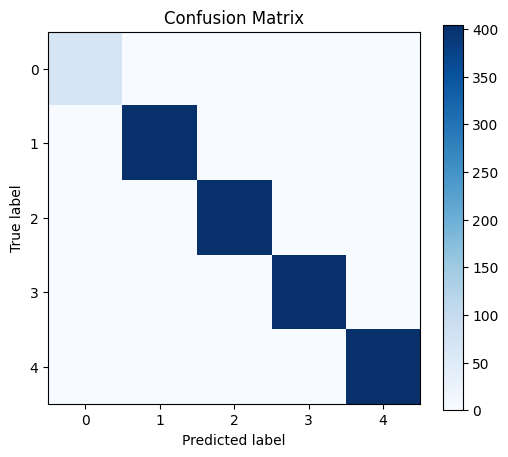

In [ ]:
y_val_pred = np.argmax(model.predict(X_val), axis=1)
print(classification_report(y_val, y_val_pred))
cm = confusion_matrix(y_val, y_val_pred)
print('Confusion matrix:\n', cm)
plt.figure(figsize=(6, 5))
plt.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
plt.title('Confusion Matrix')
plt.colorbar()
tick_marks = np.arange(len(np.unique(y)))
plt.xticks(tick_marks, tick_marks)
plt.yticks(tick_marks, tick_marks)
plt.xlabel('Predicted label')
plt.ylabel('True label')
plt.show()

# 9. Salvarea modelului si conversia


In [ ]:
model.save('cnn1d_model.h5')
np.save('scaler_mean.npy', scaler.mean_)
np.save('scaler_scale.npy', scaler.scale_)
converted_model = tf.lite.TFLiteConverter.from_keras_model(model)
tflite_model = converted_model.convert()
with open('cnn1d_model.tflite', 'wb') as f:
    f.write(tflite_model)

INFO:tensorflow:Assets written to: C:\Users\Cristi\AppData\Local\Temp\tmpvqae4ry3\assets


INFO:tensorflow:Assets written to: C:\Users\Cristi\AppData\Local\Temp\tmpvqae4ry3\assets


Saved artifact at 'C:\Users\Cristi\AppData\Local\Temp\tmpvqae4ry3'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 128, 8), dtype=tf.float32, name='keras_tensor_24')
Output Type:
  TensorSpec(shape=(None, 5), dtype=tf.float32, name=None)
Captures:
  2519662901200: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2519635582736: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2519662896784: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2519662894672: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2519662900240: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2519662902928: TensorSpec(shape=(), dtype=tf.resource, name=None)


# 10. Conversie TFLite cu cuantizare int8

In [ ]:
def representative_dataset():
    for window in X_train[:1000]:
        yield [np.expand_dims(window, axis=0).astype(np.float32)]

converter = tf.lite.TFLiteConverter.from_keras_model(model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
converter.representative_dataset = representative_dataset
converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
converter.inference_input_type = tf.int8
converter.inference_output_type = tf.int8
tflite_quant_model = converter.convert()
with open('cnn1d_model_int8.tflite', 'wb') as f:
    f.write(tflite_quant_model)
print('Saved quantized model to cnn1d_model_int8.tflite')

INFO:tensorflow:Assets written to: C:\Users\Cristi\AppData\Local\Temp\tmpluf5tjx1\assets


INFO:tensorflow:Assets written to: C:\Users\Cristi\AppData\Local\Temp\tmpluf5tjx1\assets


Saved artifact at 'C:\Users\Cristi\AppData\Local\Temp\tmpluf5tjx1'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 128, 8), dtype=tf.float32, name='keras_tensor_24')
Output Type:
  TensorSpec(shape=(None, 5), dtype=tf.float32, name=None)
Captures:
  2519662901200: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2519635582736: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2519662896784: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2519662894672: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2519662900240: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2519662902928: TensorSpec(shape=(), dtype=tf.resource, name=None)


c:\Users\Cristi\Desktop\Licenta\Model_ML_BASELINE\.venv\Lib\site-packages\tensorflow\lite\python\convert.py:863: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(


Saved quantized model to cnn1d_model_int8.tflite


# 11. Salvarea fisierelor in forma values pentru mean si scale

In [ ]:
mean = np.load("scaler_mean.npy")
scale = np.load("scaler_scale.npy")
print("float mean[] = {", ", ".join(f"{m:.8f}f" for m in mean), "};")
print("float scale[] = {", ", ".join(f"{s:.8f}f" for s in scale), "};")

float mean[] = { 0.16072655f, 1.25892021f, -10.62415710f, -0.08210014f, 0.02179371f, -0.01043591f, 24.17770593f, 200.80268127f };
float scale[] = { 0.31862916f, 0.39862019f, 0.25976664f, 0.02314163f, 0.02990474f, 0.00570753f, 0.64385888f, 52.18875332f };


# 12. scrierea modelului in bytes


In [ ]:
import os

# Alege modelul pe care vrei sa il folosesti (cel simplu sau cel cuantificat int8)
# Recomandarea mea: incepe cu cel simplu, daca e prea mare treci la cel int8
input_model_path = 'cnn1d_model.tflite' 
output_header_path = 'model_data.h'

def convert_to_c_array(input_path, output_path):
    with open(input_path, 'rb') as f:
        data = f.read()

    # Cream continutul fisierului C
    c_content = []
    c_content.append('#ifndef MODEL_DATA_H')
    c_content.append('#define MODEL_DATA_H')
    c_content.append('')
    c_content.append('#include <stdint.h>')
    c_content.append('')
    # Adaugam lungimea
    c_content.append(f'const unsigned int model_data_len = {len(data)};')
    c_content.append('')
    # Adaugam array-ul cu aliniere (CRUCIAL pentru TensorFlow Lite Micro)
    # Folosim 'const' pentru a-l tine in Flash, nu in RAM
    c_content.append('const unsigned char model_data[] __attribute__((aligned(4))) = {')
    
    # Convertim bytes in hex strings
    hex_data = [f'0x{byte:02x}' for byte in data]
    
    # Le formatam frumos, cate 12 pe linie ca sa nu crape editorul
    for i in range(0, len(hex_data), 12):
        line = ', '.join(hex_data[i:i+12])
        if i + 12 < len(hex_data):
            line += ','
        c_content.append('  ' + line)
        
    c_content.append('};')
    c_content.append('')
    c_content.append('#endif // MODEL_DATA_H')

    # Scriem fisierul
    with open(output_path, 'w') as f:
        f.write('\n'.join(c_content))
    
    print(f"Succes! Fisierul '{output_path}' a fost generat corect.")
    print(f"Marime model: {len(data)} bytes")

# Rularea conversiei
convert_to_c_array(input_model_path, output_header_path)

Succes! Fisierul 'model_data.h' a fost generat corect.
Marime model: 2078444 bytes
